# EDA biến động tải: ETTm1 & ETTm2 (bản 2)

**Mục tiêu (theo task).**
1. Tính **độ lệch chuẩn theo giờ × thứ**, làm bảng `param_profile` cho tầng phát hiện z-score.
2. Mô tả **phân phối tốc độ tăng tải trong 1 giờ**.
3. **Đếm spike tự nhiên** trong dữ liệu thật.

**Output:** bảng thống kê, ngưỡng z-score, biên độ và thời lượng sự cố bơm vào.

**Quy ước đã chốt với team.**
- `total_load = HUFL`. Lý do: HUFL ≈ MUFL + LUFL, tức điện vào phía cao áp bằng điện ra hai phía còn lại. Cộng cả ba sẽ đếm tải 2 lần.
- `rating = P99(total_load, dòng sạch, 16 tháng đầu) × RATING_COEF`. P99 là **mức tải đỉnh lịch sử**, không phải mức nguy hiểm. Hệ số là **giả định**, vì ETT không có công suất định mức thật; notebook chạy độ nhạy với 1,0 / 1,25 / 1,5.
- Chỉ dùng **16 tháng đầu** (01/07/2016 → 31/10/2017). Bên trong 16 tháng này lại chia:
  - **TRAIN** = 12 tháng đầu (07/2016 → 06/2017): dùng để **ước lượng** tham số (profile, ngưỡng).
  - **VALID** = 4 tháng sau (07/2017 → 10/2017): dùng để **kiểm tra ngoài mẫu** (ngưỡng có giữ được trên dữ liệu chưa thấy không, sự cố bơm vào có bắt được không).
  - Tham số **xuất ra cho pipeline** được ước lượng lại trên đủ 16 tháng sau khi đã kiểm tra.
- Không xóa dòng nào. Dòng nghi lỗi chỉ được **gắn cờ** và loại khỏi phép tính thống kê.

### Thay đổi so với bản trước (theo góp ý của team)

| Vị trí | Góp ý | Đã xử lý thế nào |
|---|---|---|
| Section 1 (Cell 4–6) | FLATLINE có thể loại nhầm | FLATLINE chỉ xét `HUFL`; thêm bảng phân bố độ dài chuỗi lặp, độ nhạy ngưỡng 4/8/16/96 bản ghi, và đối chiếu với kênh MUFL + LUFL. Thêm cờ `BALANCE_BREAK` (HUFL ≠ MUFL + LUFL) chỉ để ghi nhận |
| Section 2 (Cell 7–9) | Cần kiểm tra tính hợp lý khi loại | Trình bày bằng chứng (thành phần tải, OT, cân bằng) và **độ nhạy**: P99, std khi giữ và khi loại |
| Section 3 (Cell 10–11) | P99 thay đổi mạnh sau lọc | Bảng P99 theo từng cách lọc, P99 theo từng khối 4 tháng, khoảng tin cậy bootstrap theo ngày; độ nhạy theo hệ số định mức |
| Section 4 (Cell 12–14) | Độ ổn định, look-ahead | Profile ước lượng trên TRAIN, kiểm tra trên VALID; so sánh std giữa tuần chẵn và tuần lẻ; nền 7 ngày chỉ nhìn quá khứ |
| Section 5 (Cell 15–16) | Chưa kiểm tra toàn bộ cửa sổ | Một ramp chỉ hợp lệ khi **mọi** bản ghi trong cửa sổ đều sạch |
| Section 6 (Cell 17–18) | Offline vs real-time | Tách hai bộ lọc: Hampel **offline** (cửa sổ giữa, nhìn cả tương lai) và **real-time** (chỉ nhìn quá khứ) |
| Section 7 (Cell 19–20) | Chưa đủ cơ sở gọi là false alarm | Đổi tên thành **"tỷ lệ vượt ngưỡng nền"** (dữ liệu không có nhãn); chọn ngưỡng trên TRAIN, báo cáo tỷ lệ ngoài mẫu trên VALID |
| Section 8 (Cell 21–26) | Chưa kiểm chứng trên nhiều sự cố | Mô phỏng Monte Carlo 200 sự cố mỗi kịch bản mỗi trạm trên VALID, nhiều kịch bản (tốc độ, đỉnh, hệ số định mức), đo tỷ lệ phát hiện, thời gian báo trước **và** tỷ lệ báo nền khi không bơm gì |
| Section 9 (cuối file) | Kết luận mạnh hơn bằng chứng | Mỗi kết luận ghi mức độ bằng chứng và giới hạn |

## 0. Cấu hình, tải dữ liệu

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

# ---- Nguồn dữ liệu: mặc định đọc từ GitHub; có thể trỏ ETT_DATA_DIR về thư mục CSV đã tải ----
BASE_URL = os.environ.get("ETT_DATA_DIR",
                          "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/")
if not BASE_URL.endswith("/"):
    BASE_URL += "/"

# ---- Nơi lưu kết quả: trên Colab lưu vào Drive, ngoài Colab lưu cạnh notebook ----
try:
    from google.colab import drive          # chỉ có khi chạy trên Colab
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/BI || BUSINESS INTELLIGENCE || Group Project"   # sửa cho đúng thư mục của team
except ImportError:
    PROJECT_DIR = "."
OUT_DIR = os.path.join(PROJECT_DIR, "outputs_load_volatility")
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Mốc thời gian ----
CAL_START = pd.Timestamp("2016-07-01")
TRAIN_END = CAL_START + pd.DateOffset(months=12)   # 2017-07-01: hết TRAIN
CAL_END = CAL_START + pd.DateOffset(months=16)     # 2017-11-01: hết 16 tháng hiệu chuẩn

# ---- Tham số ----
STATIONS = ["ETTm1", "ETTm2"]
LOAD_COL = "HUFL"                         # total_load = HUFL (đã chốt với team)
RATING_COEF = 1.25                         # hệ số định mức mặc định (giả định); độ nhạy ở Section 3 và 8
COEF_GRID = [1.0, 1.25, 1.5]
FLAT_MIN_RECORDS = 8                       # >= 8 bản ghi (2 giờ) không đổi -> nghi cảm biến đứng yên
STEP_MIN = 15
COLORS = {"ETTm1": "#2a78d6", "ETTm2": "#eb6834"}   # mỗi trạm một màu cố định
DOW_LABELS = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
RNG = np.random.default_rng(42)            # cố định seed để kết quả Monte Carlo tái lập được

print("TRAIN:", CAL_START.date(), "->", (TRAIN_END - pd.Timedelta(minutes=15)))
print("VALID:", TRAIN_END.date(), "->", (CAL_END - pd.Timedelta(minutes=15)))
print("Kết quả lưu tại:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TRAIN: 2016-07-01 -> 2017-06-30 23:45:00
VALID: 2017-07-01 -> 2017-10-31 23:45:00
Kết quả lưu tại: /content/drive/MyDrive/BI || BUSINESS INTELLIGENCE || Group Project/outputs_load_volatility


In [ ]:
data = {}
for name in STATIONS:
    raw = pd.read_csv(BASE_URL + f"{name}.csv", parse_dates=["date"])
    df = raw[(raw["date"] >= CAL_START) & (raw["date"] < CAL_END)].sort_values("date").reset_index(drop=True)

    # Chống rò rỉ: không có bản ghi nào của giai đoạn vận hành (sau 31/10/2017)
    assert df["date"].max() < CAL_END, "Leak: data after calibration window!"
    assert df["date"].diff().dropna().eq(pd.Timedelta(minutes=STEP_MIN)).all(), "Lưới 15 phút bị hở"

    df["total_load"] = df[LOAD_COL]                       # tải đi qua máy biến áp
    df["balance_resid"] = df["HUFL"] - (df["MUFL"] + df["LUFL"])   # ≈ 0 nếu 3 kênh đo nhất quán
    df["dow"] = df["date"].dt.dayofweek
    df["hour"] = df["date"].dt.hour
    df["is_train"] = df["date"] < TRAIN_END
    data[name] = df
    print(f"{name}: {len(df):,} dòng (TRAIN {df.is_train.sum():,} | VALID {(~df.is_train).sum():,})")

ETTm1: 46,848 dòng (TRAIN 35,040 | VALID 11,808)
ETTm2: 46,848 dòng (TRAIN 35,040 | VALID 11,808)


In [ ]:
# Các hàm dùng chung
def run_lengths(s: pd.Series) -> pd.Series:
    """Độ dài chuỗi giá trị giống hệt nhau liên tiếp mà mỗi bản ghi thuộc về."""
    same = s.diff().eq(0)
    return s.groupby((~same).cumsum()).transform("size")

def run_mask(mask: pd.Series, min_len: int) -> pd.Series:
    """True cho bản ghi thuộc chuỗi True liên tiếp dài >= min_len."""
    mask = mask.fillna(False).astype(bool)
    rid = (mask != mask.shift()).cumsum()
    return mask & (mask.groupby(rid).transform("size") >= min_len)

def count_episodes(mask: pd.Series, min_len: int = 1):
    """Số đợt (chuỗi True liên tiếp) dài >= min_len, và độ dài trung bình (bản ghi)."""
    mask = mask.fillna(False).astype(bool)
    rid = (mask != mask.shift()).cumsum()
    lens = mask.groupby(rid).agg(["first", "size"])
    lens = lens.loc[lens["first"], "size"]
    lens = lens[lens >= min_len]
    return len(lens), (lens.mean() if len(lens) else 0.0)

def episodes_table(df: pd.DataFrame, mask: pd.Series, extra: dict | None = None) -> pd.DataFrame:
    """Liệt kê từng đợt của mask: bắt đầu, kết thúc, số bản ghi."""
    rid = (mask != mask.shift()).cumsum()[mask]
    agg = {"start": ("date", "min"), "end": ("date", "max"), "records": ("date", "size")}
    agg.update(extra or {})
    t = df[mask].groupby(rid).agg(**agg).reset_index(drop=True)
    t["hours"] = t["records"] * STEP_MIN / 60
    return t

def build_profile(frame: pd.DataFrame, col: str) -> pd.DataFrame:
    """Thống kê theo ô (thứ, giờ): mean, std, median, MAD×1,4826, số điểm."""
    g = frame.groupby(["dow", "hour"])[col]
    prof = g.agg(mean="mean", std="std", median="median", n="size")
    prof["mad_sigma"] = g.apply(lambda s: (s - s.median()).abs().median() * 1.4826)
    return prof

## Section 1. Chất lượng dữ liệu (gắn cờ, không xóa)

Ba câu hỏi:
1. Chuỗi giá trị lặp lại bao lâu thì đáng nghi? Xem **phân bố độ dài chuỗi lặp** của `total_load` (HUFL) để chọn ngưỡng có căn cứ.
2. Ngưỡng 8 bản ghi có làm thay đổi kết quả không? Chạy **độ nhạy** 4 / 8 / 16 / 96.
3. Dòng bị gắn cờ có thật là lỗi không? Đối chiếu với kênh độc lập **MUFL + LUFL**: nếu kênh đó cũng đứng yên cùng lúc thì gần như chắc chắn là dữ liệu bị điền giữ giá trị (forward-fill), không phải tải thật đứng yên.

In [ ]:
# 1a. Phân bố độ dài chuỗi lặp (đếm theo CHUỖI, không theo dòng)
rows = []
for name, df in data.items():
    s = df["total_load"]
    runs = s.groupby((~s.diff().eq(0)).cumsum()).size()
    bins = pd.cut(runs, [0, 1, 2, 3, 4, 7, 15, 95, 10**6], labels=["1", "2", "3", "4", "5–7", "8–15", "16–95", "≥96"])
    rows.append(bins.value_counts().sort_index().rename(name))
run_dist = pd.DataFrame(rows)
run_dist.columns.name = "Độ dài chuỗi (bản ghi)"
display(run_dist)

Độ dài chuỗi (bản ghi),1,2,3,4,5–7,8–15,16–95,≥96
ETTm1,41958,1643,104,11,3,1,1,11
ETTm2,43229,923,26,1,2,2,7,11


In [ ]:
# 1b. Độ nhạy theo ngưỡng FLATLINE + đối chiếu kênh MUFL+LUFL
sens_rows = []
for name, df in data.items():
    ml_runs = run_lengths(df["MUFL"] + df["LUFL"])
    for k in [4, 8, 16, 96]:
        fl = run_lengths(df["total_load"]) >= k
        sens_rows.append({
            "Trạm": name, "Ngưỡng (bản ghi)": k,
            "Dòng bị cờ": int(fl.sum()), "% dòng": round(fl.mean() * 100, 2),
            "% trong số đó MUFL+LUFL cũng đứng yên": round(((ml_runs >= k) & fl).sum() / max(fl.sum(), 1) * 100, 1),
            "P99 total_load sau khi loại": round(df.loc[~fl, "total_load"].quantile(0.99), 2),
        })
flat_sens = pd.DataFrame(sens_rows).set_index(["Trạm", "Ngưỡng (bản ghi)"])
display(flat_sens)

Dòng bị cờ  % dòng  % trong số đó MUFL+LUFL cũng đứng yên  P99 total_load sau khi loại
Trạm  Ngưỡng (bản ghi)                                                                                        
ETTm1 4                       1292    2.76                                   95.6                        18.89
      8                       1233    2.63                                   99.2                        18.89
      16                      1224    2.61                                   99.9                        18.89
      96                      1206    2.57                                   99.9                        18.89
ETTm2 4                       1695    3.62                                   92.2                        60.19
      8                       1681    3.59                                   91.6                        60.23
      16                      1656    3.53                                   90.6                        60.23
      96                      1284    2.74                                   99.9                        60.18

In [ ]:
# 1c. Gắn cờ chính thức
for name, df in data.items():
    df["flag_flat"] = run_lengths(df["total_load"]) >= FLAT_MIN_RECORDS
    # BALANCE_BREAK: HUFL lệch khỏi MUFL+LUFL quá 10 lần độ phân tán thường ngày, kéo dài >= 1 giờ.
    # Chỉ GHI NHẬN (lỗi nằm ở kênh M hoặc L), không loại khỏi thống kê của HUFL.
    r = df["balance_resid"]
    sigma = (r - r.median()).abs().median() * 1.4826
    df["flag_balance"] = run_mask((r - r.median()).abs() > max(10 * sigma, 1.0), 4)
    df["flag_neg_load"] = df["total_load"] < 0
    df["flag_day31"] = (df["date"].dt.day == 31) & df["flag_flat"]

dq = pd.DataFrame({name: {
    "FLATLINE (dòng)": int(df.flag_flat.sum()),
    "  trong đó: ngày 31 bị lặp": int(df.flag_day31.sum()),
    "BALANCE_BREAK (dòng, chỉ ghi nhận)": int(df.flag_balance.sum()),
    "total_load âm (dòng, chỉ ghi nhận)": int(df.flag_neg_load.sum()),
} for name, df in data.items()})
display(dq)

for name, df in data.items():
    print(f"\n{name}: các đoạn FLATLINE")
    display(episodes_table(df, df["flag_flat"]))
    print(f"{name}: các đoạn BALANCE_BREAK")
    display(episodes_table(df, df["flag_balance"]))

,ETTm1,ETTm2
FLATLINE (dòng),1233,1681
trong đó: ngày 31 bị lặp,960,960
"BALANCE_BREAK (dòng, chỉ ghi nhận)",561,4359
"total_load âm (dòng, chỉ ghi nhận)",5156,0



ETTm1: các đoạn FLATLINE


,start,end,records,hours
0,2016-07-30 23:45:00,2016-07-31 23:45:00,97,24.25
1,2016-08-30 23:30:00,2016-08-31 23:45:00,98,24.50
2,2016-10-30 23:45:00,2016-10-31 23:45:00,97,24.25
3,2016-12-05 08:15:00,2016-12-07 18:45:00,235,58.75
4,2016-12-30 23:45:00,2016-12-31 23:45:00,97,24.25
5,2017-01-09 17:00:00,2017-01-09 21:15:00,18,4.50
6,2017-01-30 23:45:00,2017-01-31 23:45:00,97,24.25
7,2017-03-30 23:45:00,2017-03-31 23:45:00,97,24.25
8,2017-05-30 23:45:00,2017-05-31 23:45:00,97,24.25
9,2017-07-30 23:45:00,2017-07-31 23:45:00,97,24.25


ETTm1: các đoạn BALANCE_BREAK


,start,end,records,hours
0,2017-07-23 21:00:00,2017-07-29 17:00:00,561,140.25



ETTm2: các đoạn FLATLINE


,start,end,records,hours
0,2016-07-30 23:45:00,2016-07-31 23:45:00,97,24.25
1,2016-08-10 14:15:00,2016-08-11 10:00:00,80,20.00
2,2016-08-30 23:30:00,2016-08-31 23:45:00,98,24.50
3,2016-10-30 23:45:00,2016-10-31 23:45:00,97,24.25
4,2016-12-18 08:00:00,2016-12-18 18:00:00,41,10.25
5,2016-12-30 23:45:00,2016-12-31 23:45:00,97,24.25
6,2017-01-30 23:45:00,2017-01-31 23:45:00,97,24.25
7,2017-03-30 23:45:00,2017-03-31 23:45:00,97,24.25
8,2017-04-10 11:45:00,2017-04-13 17:45:00,313,78.25
9,2017-04-14 14:45:00,2017-04-15 12:15:00,87,21.75


ETTm2: các đoạn BALANCE_BREAK


,start,end,records,hours
0,2016-08-11 00:15:00,2016-08-11 10:30:00,42,10.50
1,2016-12-18 08:00:00,2016-12-18 18:00:00,41,10.25
2,2017-04-14 14:45:00,2017-04-15 12:15:00,87,21.75
3,2017-04-17 11:15:00,2017-04-18 09:45:00,91,22.75
4,2017-04-19 19:30:00,2017-06-01 11:45:00,4098,1024.50


> **Giải thích kết quả.**
>
> - **Cell 4 (độ dài chuỗi lặp).** Gần như mọi chuỗi giá trị lặp chỉ dài 1–4 bản ghi. Chuỗi 5–15 bản ghi rất hiếm (ETTm1: 4 chuỗi, ETTm2: 4 chuỗi), rồi nhảy lên nhóm ≥ 96 bản ghi (11 chuỗi mỗi trạm, đa số là ngày 31). Có một khoảng trống rõ giữa "lặp tự nhiên" và "đứng yên bất thường", nên ngưỡng 8 bản ghi (2 giờ) nằm trong khoảng trống đó.
> - **Cell 5 (độ nhạy).** Đổi ngưỡng từ 4 lên 96 bản ghi, số dòng bị gắn cờ chỉ đổi từ 2,76% xuống 2,57% (ETTm1) và 3,62% xuống 2,74% (ETTm2). P99 sau khi loại gần như không đổi (ETTm1 18,89; ETTm2 60,18–60,23). Ở ngưỡng 8, 99% (ETTm1) và 92% (ETTm2) số dòng bị cờ cũng đứng yên ở kênh MUFL + LUFL. Hai kênh cùng đứng yên một lúc là dấu hiệu lỗi ghi nhận, không phải tải thật đứng yên. **Kết luận:** FLATLINE ở ngưỡng 8 không loại nhầm đáng kể, và kể cả có loại nhầm thì P99 cũng không đổi.
> - **Cell 6 (cờ chính thức).** 960 dòng mỗi trạm là ngày 31 bị lặp (10 tháng có ngày 31). `BALANCE_BREAK` chỉ ghi nhận, không loại: ETTm1 có 1 đợt (23–29/07/2017), ETTm2 chủ yếu là đợt 19/04 → 01/06/2017 khi MUFL bị kẹt ở 88,3. Vì `total_load = HUFL` nên MUFL kẹt không còn làm sai tải. ETTm1 có 5.156 dòng tải âm: đây là dòng công suất ngược (nhiều khả năng từ điện mặt trời phía trung áp), giữ nguyên, không phải lỗi.

## Section 2. Đợt tải cực đoan tự nhiên

Nếu để các đợt bất thường **thật** trong dữ liệu "bình thường", std và P99 sẽ phồng lên, làm hệ thống kém nhạy với đúng loại sự cố cần bắt. Ngược lại, loại quá tay thì làm ngưỡng "đẹp" giả tạo. Vì vậy section này: (1) phát hiện theo quy tắc rõ ràng (z > 4 liên tục ≥ 4 giờ, trên profile tạm tính), (2) trình bày bằng chứng, (3) đo **độ nhạy** của kết quả khi giữ và khi loại.

In [ ]:
EXTREME_Z, EXTREME_MIN_LEN = 4.0, 16
for name, df in data.items():
    base = df[~df["flag_flat"]]
    p0 = build_profile(base, "total_load")
    j = df.join(p0[["mean", "std"]], on=["dow", "hour"])
    z0 = ((df["total_load"] - j["mean"]) / j["std"]).where(~df["flag_flat"])
    df["flag_extreme"] = run_mask(z0 > EXTREME_Z, EXTREME_MIN_LEN)
    df["ok"] = ~df["flag_flat"] & ~df["flag_extreme"]
    ext = df["flag_extreme"]
    if ext.any():
        t = episodes_table(df, ext, {"peak_HUFL": ("HUFL", "max"), "peak_OT": ("OT", "max")})
        print(f"{name}: {len(t)} đợt EXTREME_EPISODE")
        display(t.round({"peak_HUFL": 2, "peak_OT": 2}))
    else:
        print(f"{name}: không có đợt EXTREME_EPISODE")

ETTm1: không có đợt EXTREME_EPISODE
ETTm2: 1 đợt EXTREME_EPISODE


,start,end,records,peak_HUFL,peak_OT,hours
0,2017-04-17 11:15:00,2017-04-19 19:15:00,225,107.89,49.16,56.25


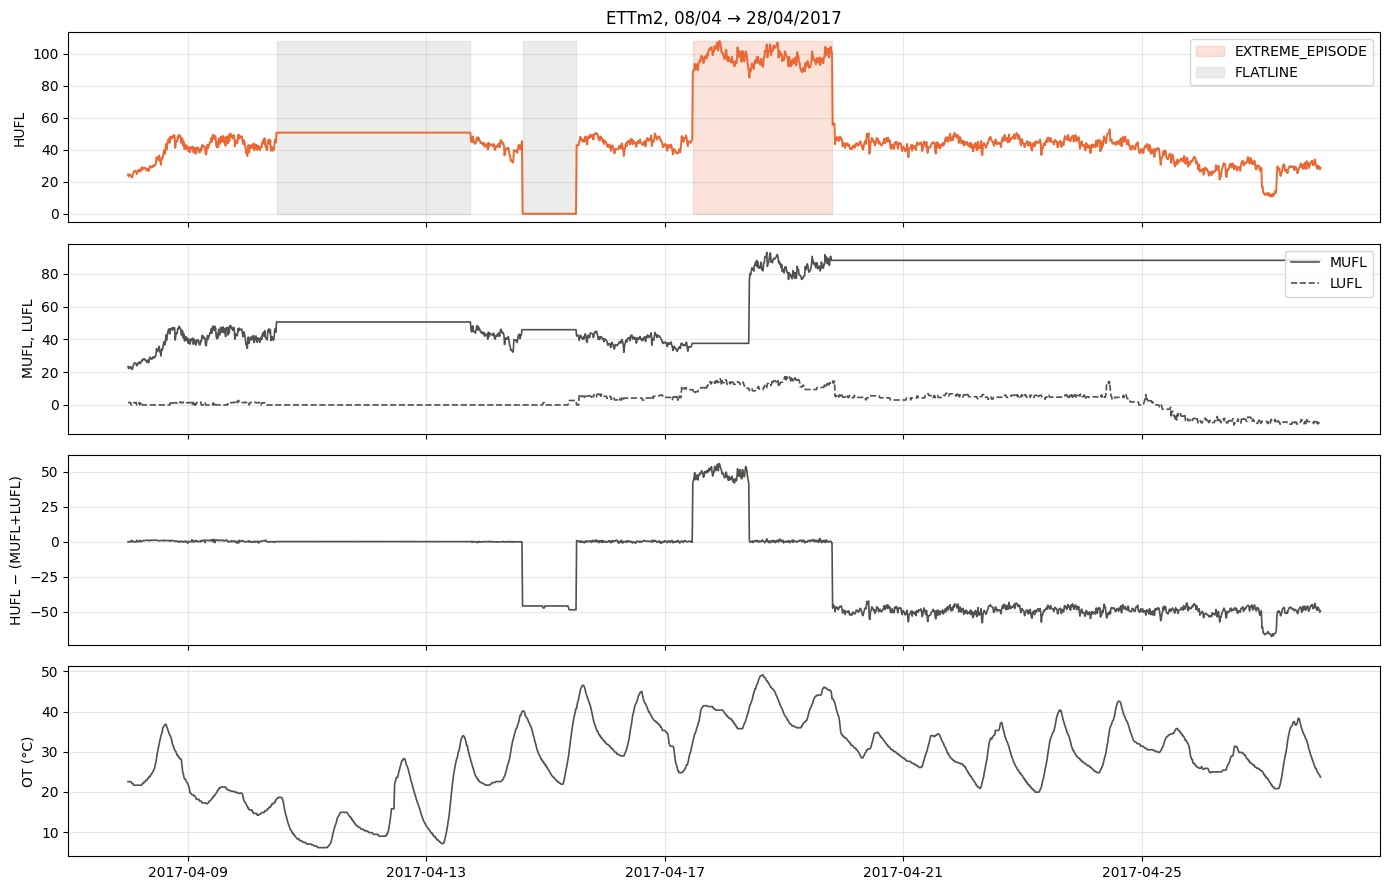

In [ ]:
# Bằng chứng: thành phần tải, cân bằng và OT quanh đợt cực đoan của ETTm2 (mỗi biến một ô, chung trục thời gian)
df = data["ETTm2"]
w = df[(df["date"] >= "2017-04-08") & (df["date"] < "2017-04-28")]
fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
axes[0].plot(w["date"], w["total_load"], color=COLORS["ETTm2"], lw=1.4)
for flag, color, label in [("flag_extreme", "#eb6834", "EXTREME_EPISODE"), ("flag_flat", "#9b9a95", "FLATLINE")]:
    axes[0].fill_between(w["date"], w["total_load"].min(), w["total_load"].max(), where=w[flag],
                         color=color, alpha=0.18, label=label)
axes[0].set_ylabel("HUFL"); axes[0].legend(loc="upper right")
for c, ls in [("MUFL", "-"), ("LUFL", "--")]:
    axes[1].plot(w["date"], w[c], color="#52514e", lw=1.2, ls=ls, label=c)
axes[1].set_ylabel("MUFL, LUFL"); axes[1].legend(loc="upper right")
axes[2].plot(w["date"], w["balance_resid"], color="#52514e", lw=1.2)
axes[2].set_ylabel("HUFL − (MUFL+LUFL)")
axes[3].plot(w["date"], w["OT"], color="#52514e", lw=1.2)
axes[3].set_ylabel("OT (°C)")
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].set_title("ETTm2, 08/04 → 28/04/2017")
plt.tight_layout(); plt.show()

In [ ]:
# Độ nhạy: giữ hay loại đợt cực đoan thì P99 và std thay đổi bao nhiêu?
rows = []
for name, df in data.items():
    keep = df[~df["flag_flat"]]
    drop = df[df["ok"]]
    rows.append({
        "Trạm": name,
        "P99 (giữ extreme)": keep["total_load"].quantile(0.99),
        "P99 (loại extreme)": drop["total_load"].quantile(0.99),
        "Median std ô giờ×thứ (giữ)": build_profile(keep, "total_load")["std"].median(),
        "Median std ô giờ×thứ (loại)": build_profile(drop, "total_load")["std"].median(),
        "Dòng extreme": int(df["flag_extreme"].sum()),
    })
display(pd.DataFrame(rows).set_index("Trạm").round(2))

,P99 (giữ extreme),P99 (loại extreme),Median std ô giờ×thứ (giữ),Median std ô giờ×thứ (loại),Dòng extreme
Trạm,,,,,
ETTm1,18.89,18.89,3.58,3.58,0
ETTm2,60.23,58.55,8.85,8.42,225


> **Giải thích kết quả.**
>
> - **Cell 7.** Chỉ ETTm2 có một đợt tải cực đoan: 17/04/2017 11:15 → 19/04/2017 19:15 (225 bản ghi, 56 giờ). HUFL lên tới 107,9, khoảng gấp 2,5 lần mức thường (~40). ETTm1 không có đợt nào.
> - **Cell 8 (bằng chứng).** Bằng chứng đi theo hai hướng:
>   - *Ủng hộ tải thật:* OT lên 49,2 °C, cao nhất giai đoạn, và vẫn giữ chu kỳ ngày. Nếu chỉ là lỗi cảm biến tải thì OT không có lý do để nóng lên.
>   - *Ủng hộ lỗi đo:* ngày 17/04 HUFL nhảy lên nhưng MUFL + LUFL chưa nhảy (lệch cân bằng ≈ +50). Ngày 18/04 MUFL nhảy theo. Ngày 19/04 HUFL rơi về nhưng MUFL đứng yên luôn (lệch ≈ −50 kéo dài tới 01/06).
>   - Vậy dữ liệu **không đủ để kết luận là lỗi**. Có thể là một sự kiện vận hành thật (chuyển tải, đóng cắt) cộng với lỗi kênh đo đi kèm.
> - **Cách xử lý và lý do.** Giữ nguyên dòng, gắn cờ `EXTREME_EPISODE`, chỉ loại khỏi **hiệu chuẩn**. Profile cần mô tả biến động *bình thường*, và một đợt 56 giờ gấp 2,5 lần mức thường sẽ thổi phồng std. Đợt này nên giữ lại làm **ca kiểm thử thật** cho hệ thống cảnh báo.
> - **Cell 9 (độ nhạy).** Loại đợt này làm P99 ETTm2 giảm từ 60,23 xuống 58,55 (−2,8%) và median std giảm từ 8,85 xuống 8,42 (−5%). Mức thay đổi nhỏ hơn biên độ bất định của P99 ở Section 3, nên quyết định giữ hay loại không làm đổi kết luận.

## Section 3. Định mức (`rating`) và độ ổn định của P99

`rating = P99 × RATING_COEF`. Vì mọi ngưỡng tính theo `% định mức` đều dựa vào con số này, cần biết P99 **ổn định đến đâu**:
- Thay đổi bao nhiêu theo cách lọc dữ liệu?
- Thay đổi bao nhiêu giữa các khối 4 tháng?
- Khoảng tin cậy 95% (bootstrap theo **ngày**, để giữ nguyên cấu trúc trong ngày) rộng bao nhiêu?

In [ ]:
def bootstrap_p99_by_day(s: pd.Series, dates: pd.Series, n_boot: int = 300) -> tuple:
    day = dates.dt.normalize()
    groups = [g.values for _, g in s.groupby(day)]
    vals = []
    for _ in range(n_boot):
        pick = RNG.integers(0, len(groups), len(groups))
        vals.append(np.quantile(np.concatenate([groups[i] for i in pick]), 0.99))
    return tuple(np.quantile(vals, [0.025, 0.975]))

rows, block_rows = [], []
for name, df in data.items():
    lo, hi = bootstrap_p99_by_day(df.loc[df.ok, "total_load"], df.loc[df.ok, "date"])
    rows.append({
        "Trạm": name,
        "P99 mọi dòng": df["total_load"].quantile(0.99),
        "P99 bỏ FLATLINE": df.loc[~df.flag_flat, "total_load"].quantile(0.99),
        "P99 bỏ FLATLINE + EXTREME (dùng)": df.loc[df.ok, "total_load"].quantile(0.99),
        "KTC 95% bootstrap theo ngày": f"{lo:.2f} – {hi:.2f}",
    })
    blk = df[df.ok].groupby(pd.cut(df.loc[df.ok, "date"], pd.date_range(CAL_START, CAL_END, freq="4MS")))["total_load"].quantile(0.99)
    block_rows.append(blk.rename(name))
display(pd.DataFrame(rows).set_index("Trạm").round(2))
blocks = pd.DataFrame(block_rows).round(2)
blocks.columns = [f"{c.left:%m/%Y}–{(c.right - pd.Timedelta(days=1)):%m/%Y}" for c in blocks.columns]
print("P99 theo từng khối 4 tháng (dòng sạch):")
display(blocks)

/tmp/ipykernel_1226/2369169716.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  blk = df[df.ok].groupby(pd.cut(df.loc[df.ok, "date"], pd.date_range(CAL_START, CAL_END, freq="4MS")))["total_load"].quantile(0.99)
/tmp/ipykernel_1226/2369169716.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  blk = df[df.ok].groupby(pd.cut(df.loc[df.ok, "date"], pd.date_range(CAL_START, CAL_END, freq="4MS")))["total_load"].quantile(0.99)


,P99 mọi dòng,P99 bỏ FLATLINE,P99 bỏ FLATLINE + EXTREME (dùng),KTC 95% bootstrap theo ngày
Trạm,,,,
ETTm1,19.56,18.89,18.89,18.15 – 19.36
ETTm2,60.06,60.23,58.55,57.47 – 59.81


P99 theo từng khối 4 tháng (dòng sạch):


,07/2016–10/2016,11/2016–02/2017,03/2017–06/2017,07/2017–10/2017
ETTm1,19.96,16.08,14.60,19.62
ETTm2,60.98,58.15,54.03,50.42


In [ ]:
P99 = {name: df.loc[df.ok, "total_load"].quantile(0.99) for name, df in data.items()}
rating = {name: P99[name] * RATING_COEF for name in STATIONS}
for name, df in data.items():
    df["load_pct"] = df["total_load"] / rating[name] * 100

# Phân bố load_pct theo từng hệ số định mức (cùng dữ liệu, chỉ đổi mẫu số)
rows = []
for name, df in data.items():
    for coef in COEF_GRID:
        pct = df.loc[df.ok, "total_load"] / (P99[name] * coef) * 100
        rows.append({"Trạm": name, "Hệ số": coef, "rating": round(P99[name] * coef, 2),
                     **{f"P{int(q*100)}": round(pct.quantile(q), 1) for q in [0.5, 0.85, 0.95, 0.99]},
                     "Max": round(pct.max(), 1)})
display(pd.DataFrame(rows).set_index(["Trạm", "Hệ số"]))

rating   P50   P85   P95    P99    Max
Trạm  Hệ số                                        
ETTm1 1.00    18.89  44.7  67.4  81.2  100.0  128.0
      1.25    23.61  35.7  53.9  65.0   80.0  102.4
      1.50    28.33  29.8  44.9  54.1   66.7   85.3
ETTm2 1.00    58.55  68.8  83.0  91.1  100.0  113.4
      1.25    73.19  55.0  66.4  72.9   80.0   90.8
      1.50    87.83  45.9  55.3  60.8   66.7   75.6

> **Giải thích kết quả.**
>
> - **Cell 10 (P99 thay đổi bao nhiêu sau lọc).** ETTm1: 19,56 → 18,89 (−3,4%, chủ yếu do bỏ ngày 31). ETTm2: 60,06 → 60,23 → 58,55 (tối đa −2,8%). Mức thay đổi do lọc cùng cỡ với khoảng tin cậy bootstrap theo ngày (ETTm1 18,15–19,36; ETTm2 57,47–59,81).
> - Nguồn bất định **lớn hơn nhiều** là mùa và hệ số: P99 theo khối 4 tháng của ETTm1 dao động 14,6–20,0; ETTm2 giảm dần từ 61,0 xuống 50,4. Đổi hệ số từ 1,0 sang 1,5 làm định mức thay đổi 50%. **Kết luận:** góp ý "P99 thay đổi mạnh sau lọc" không đúng với `total_load = HUFL` (bản trước dùng H+M+L nên MUFL kẹt kéo P99 lên). Thứ thật sự quyết định ngưỡng là **hệ số** và **mùa**.
> - Ngưỡng z-score **không phụ thuộc** định mức vì z tính trên đơn vị tải. Định mức chỉ ảnh hưởng `load_pct`, ramp tính theo pp và kịch bản bơm.
> - **Cell 11 (chọn hệ số).** Với hệ số 1,0, tải lịch sử đã lên 128% (ETTm1) và 113% (ETTm2), tức là "quá tải" nhiều lần trong khi OT chỉ ~46 / 59 °C, rất xa giới hạn nhiệt IEC. Điều đó không hợp lý. Với 1,25, P99 = 80% và max = 102% / 91%, phù hợp giả định "đỉnh lịch sử ≈ 80% định mức". Notebook dùng **1,25 làm mặc định**, kèm độ nhạy 1,0 / 1,5. Đây vẫn là **giả định**, cần ghi rõ trong báo cáo.
> - Lưu ý: P99 của ETTm2 giảm dần theo thời gian, nên khi vận hành, ngưỡng cố định có thể ít báo hơn dự kiến.

## Section 4. Bước (1): Độ lệch chuẩn theo giờ × thứ

**Chống look-ahead:** profile dùng để đánh giá (Section 6–8) được ước lượng **chỉ trên TRAIN**. Profile xuất cho pipeline (`param_profile_<trạm>.csv`) ước lượng lại trên đủ 16 tháng sau khi đã kiểm tra.

**Hai biến thể z-score** được mang theo để so sánh:
- **z thô** (đúng kế hoạch): `z = (load − mean[thứ, giờ]) / std[thứ, giờ]`.
- **z phần dư**: trừ trước một **nền 7 ngày gần nhất** (trung vị của 7 ngày **trước** thời điểm đang xét, không dùng tương lai), rồi mới chuẩn hoá theo ô giờ × thứ. Mục đích: tách phần thay đổi chậm theo tuần/mùa ra khỏi std.

In [ ]:
for name, df in data.items():
    # closed="left": cửa sổ 7 ngày KẾT THÚC TRƯỚC bản ghi hiện tại -> không nhìn tương lai, kể cả chính nó
    s = df.set_index("date")["total_load"].where(df.set_index("date").index.isin(df.loc[df.ok, "date"]))
    df["baseline_7d"] = s.rolling("7D", min_periods=96, closed="left").median().values
    df["resid_7d"] = df["total_load"] - df["baseline_7d"]

profiles_train, profiles_resid_train, profiles_cal, profiles_resid_cal = {}, {}, {}, {}
for name, df in data.items():
    tr = df[df.ok & df.is_train]
    profiles_train[name] = build_profile(tr, "total_load")
    profiles_resid_train[name] = build_profile(tr.dropna(subset=["resid_7d"]), "resid_7d")
    cal = df[df.ok]
    profiles_cal[name] = build_profile(cal, "total_load")
    profiles_resid_cal[name] = build_profile(cal.dropna(subset=["resid_7d"]), "resid_7d")
    for tag, prof in [("", profiles_cal[name]), ("resid_", profiles_resid_cal[name])]:
        prof.round(4).reset_index().assign(station=name, load_col=LOAD_COL).to_csv(
            f"{OUT_DIR}/param_profile_{tag}{name}.csv", index=False)

    p = profiles_cal[name]
    print(f"\n{name}: 168 ô, mỗi ô {p['n'].min()}–{p['n'].max()} điểm (16 tháng, dòng sạch)")
    display(p[["mean", "std", "median", "mad_sigma"]].describe().loc[["min", "25%", "50%", "75%", "max"]].round(2))


ETTm1: 168 ô, mỗi ô 264–276 điểm (16 tháng, dòng sạch)


,mean,std,median,mad_sigma
min,-0.18,1.81,1.91,1.14
25%,3.69,3.00,6.39,2.48
50%,8.92,3.58,7.84,3.05
75%,10.90,6.07,10.85,5.21
max,11.93,9.26,11.65,9.98



ETTm2: 168 ô, mỗi ô 252–276 điểm (16 tháng, dòng sạch)


,mean,std,median,mad_sigma
min,35.30,6.78,36.48,6.40
25%,37.25,7.75,38.58,7.95
50%,39.86,8.42,40.54,8.57
75%,41.50,8.96,42.81,9.27
max,44.47,10.14,45.57,11.36


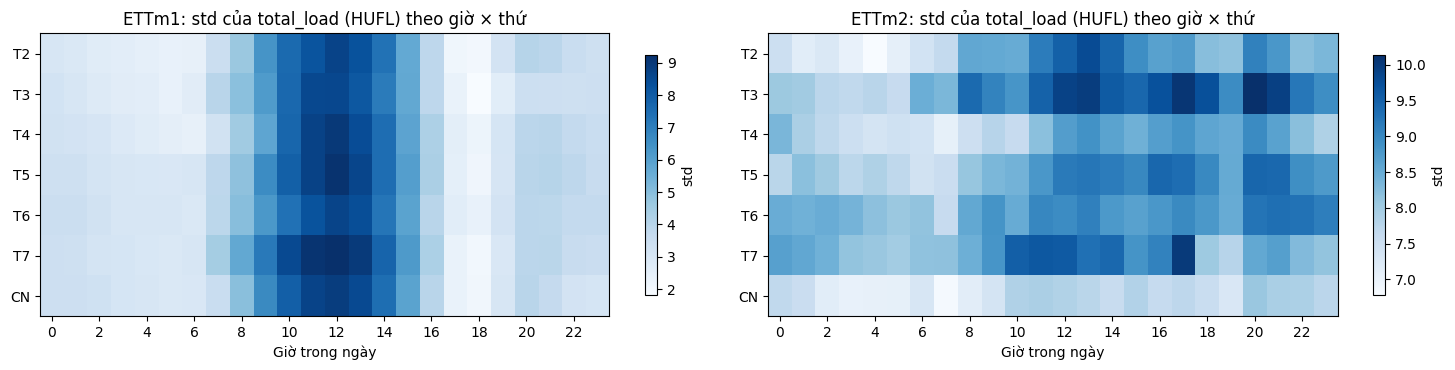

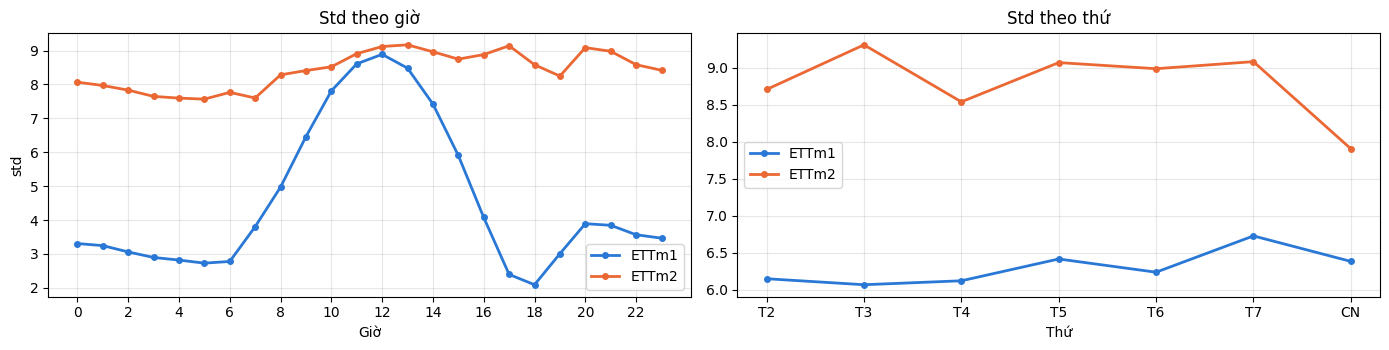

,ETTm1,ETTm2
std max/min theo GIỜ,4.25,1.21
std max/min theo THỨ,1.11,1.18
Median std (thô),3.58,8.42
Median std (sau trừ nền 7 ngày),2.90,5.25


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, name in zip(axes, STATIONS):
    pv = profiles_cal[name]["std"].unstack("hour")
    im = ax.imshow(pv, aspect="auto", cmap="Blues")
    ax.set_yticks(range(7)); ax.set_yticklabels(DOW_LABELS)
    ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Giờ trong ngày")
    ax.set_title(f"{name}: std của total_load (HUFL) theo giờ × thứ")
    fig.colorbar(im, ax=ax, shrink=0.85, label="std")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for name, df in data.items():
    ok = df[df.ok]
    axes[0].plot(ok.groupby("hour")["total_load"].std(), marker="o", ms=4, lw=2, color=COLORS[name], label=name)
    axes[1].plot(ok.groupby("dow")["total_load"].std(), marker="o", ms=4, lw=2, color=COLORS[name], label=name)
axes[0].set(title="Std theo giờ", xlabel="Giờ", ylabel="std", xticks=range(0, 24, 2))
axes[1].set(title="Std theo thứ", xlabel="Thứ", xticks=range(7)); axes[1].set_xticklabels(DOW_LABELS)
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

ratio = pd.DataFrame({name: {
    "std max/min theo GIỜ": df[df.ok].groupby("hour")["total_load"].std().pipe(lambda s: s.max() / s.min()),
    "std max/min theo THỨ": df[df.ok].groupby("dow")["total_load"].std().pipe(lambda s: s.max() / s.min()),
    "Median std (thô)": profiles_cal[name]["std"].median(),
    "Median std (sau trừ nền 7 ngày)": profiles_resid_cal[name]["std"].median(),
} for name, df in data.items()}).round(2)
display(ratio)

In [ ]:
# Độ ổn định của profile: ước lượng trên 2 nửa dữ liệu độc lập rồi so sánh từng ô.
#  - Tuần chẵn vs tuần lẻ: hai nửa trải đều mùa, nên chênh lệch phản ánh nhiễu lấy mẫu.
#  - TRAIN vs VALID: chênh lệch phản ánh thay đổi theo thời gian (mùa, chế độ vận hành).
rows = []
for name, df in data.items():
    ok = df[df.ok].dropna(subset=["resid_7d"])
    week = ok["date"].dt.isocalendar().week
    for col, label in [("total_load", "z thô"), ("resid_7d", "z phần dư")]:
        for a_mask, b_mask, split in [(week % 2 == 0, week % 2 == 1, "tuần chẵn vs lẻ"),
                                      (ok.is_train, ~ok.is_train, "TRAIN vs VALID")]:
            sa = build_profile(ok[a_mask], col)["std"]
            sb = build_profile(ok[b_mask], col)["std"]
            rows.append({"Trạm": name, "Biến thể": label, "So sánh": split,
                         "Tương quan std 168 ô": sa.corr(sb),
                         "Trung vị |chênh lệch| (%)": ((sa - sb).abs() / ((sa + sb) / 2)).median() * 100})
stab = pd.DataFrame(rows).set_index(["Trạm", "Biến thể", "So sánh"]).round(2)
display(stab)

Tương quan std 168 ô  Trung vị |chênh lệch| (%)
Trạm  Biến thể  So sánh                                                         
ETTm1 z thô     tuần chẵn vs lẻ                  0.97                       8.86
                TRAIN vs VALID                   0.89                      19.12
      z phần dư tuần chẵn vs lẻ                  0.96                       8.87
                TRAIN vs VALID                   0.92                      13.68
ETTm2 z thô     tuần chẵn vs lẻ                  0.29                      21.41
                TRAIN vs VALID                   0.24                      29.73
      z phần dư tuần chẵn vs lẻ                  0.32                      20.36
                TRAIN vs VALID                  -0.05                      21.35

> **Giải thích kết quả.**
>
> - **Cell 12–13.** Mỗi ô giờ × thứ có ~252–276 điểm (16 tháng, dòng sạch), đủ để ước lượng std. ETTm1: std thay đổi mạnh theo **giờ** (ô lớn nhất gấp 4,25 lần ô nhỏ nhất) nhưng gần như không đổi theo **thứ** (1,11). ETTm2: gần như phẳng (1,21 theo giờ, 1,18 theo thứ).
> - Trừ nền 7 ngày làm std giảm: ETTm1 3,58 → 2,90, ETTm2 8,42 → 5,25. Ở ETTm2, phần lớn "biến động" thật ra là mức tải trôi theo tuần/mùa, và nền 7 ngày hấp thụ phần đó. Đây là lý do z phần dư nhạy hơn z thô.
> - **Cell 14 (độ ổn định).**
>   - *ETTm1 ổn định:* tương quan std 168 ô giữa tuần chẵn và tuần lẻ là 0,97, giữa TRAIN và VALID là 0,89 (phần dư 0,92). Dùng profile theo từng ô là hợp lý.
>   - *ETTm2 không ổn định theo ô:* tương quan chỉ 0,24–0,32 (phần dư TRAIN vs VALID ≈ 0). Lý do là std gần bằng nhau ở mọi ô, nên khác biệt giữa các ô chủ yếu là nhiễu ước lượng (chênh 20–30%). **Gợi ý:** ETTm2 nên dùng std gộp theo giờ (24 ô) hoặc một std chung, thay vì 168 ô. Notebook chưa đổi, team quyết định.
> - **Look-ahead.** Nền 7 ngày dùng `closed="left"` nên chỉ nhìn quá khứ. Kiểm tra ngoài mẫu dùng profile ước lượng trên TRAIN. File `param_profile_*.csv` xuất cho pipeline được ước lượng lại trên đủ 16 tháng và không chạm vào 8 tháng vận hành.

## Section 5. Bước (2): Phân phối tốc độ tăng tải

`ramp_k(t) = load_pct(t) − load_pct(t − k)`, đơn vị **điểm % định mức (pp)**. Một ramp chỉ được tính khi **mọi bản ghi** trong cửa sổ `[t − k, t]` đều sạch (không chỉ hai đầu), để một đoạn đứng yên ở giữa không tạo ra ramp giả.

In [ ]:
RAMP_STEPS = {"15m": 1, "1h": 4, "2h": 8, "4h": 16}
Q_LIST = [0.01, 0.05, 0.50, 0.90, 0.95, 0.99, 0.999]
ramp_rows = []
for name, df in data.items():
    for label, k in RAMP_STEPS.items():
        all_ok = df["ok"].astype(int).rolling(k + 1).min().eq(1)       # toàn bộ k+1 bản ghi đều sạch
        r = df["load_pct"].diff(k).where(all_ok)
        df[f"ramp_{label}"] = r
        s = r.dropna()
        ramp_rows.append({"Trạm": name, "Cửa sổ": label, "Số ramp hợp lệ": len(s),
                          **{f"P{q*100:g}": s.quantile(q) for q in Q_LIST}, "max": s.max()})
ramp_table = pd.DataFrame(ramp_rows).set_index(["Trạm", "Cửa sổ"]).round(2)
ramp_table.to_csv(f"{OUT_DIR}/ramp_quantiles_pct_rating.csv")
print(f"Đơn vị: pp định mức, với RATING_COEF = {RATING_COEF}")
display(ramp_table)

Đơn vị: pp định mức, với RATING_COEF = 1.25


Số ramp hợp lệ     P1     P5   P50    P90    P95    P99  P99.9     max
Trạm  Cửa sổ                                                                        
ETTm1 15m              45602 -18.15  -8.23  0.00   5.39   7.94  16.74  37.85   72.06
      1h               45563 -33.48 -18.44  0.00  11.06  16.74  30.92  53.62   82.27
      2h               45511 -53.34 -29.79  0.28  17.59  27.23  47.95  65.96   84.26
      4h               45407 -81.99 -51.06  0.57  27.52  47.66  74.89  90.95  107.80
ETTm2 15m              44921  -6.98  -4.58  0.11   3.32   4.35   6.41   9.62   43.61
      1h               44861 -10.30  -6.87  0.00   5.26   6.98  10.64  16.48   46.01
      2h               44785 -12.13  -8.24 -0.11   6.41   8.58  13.05  20.54   51.50
      4h               44633 -15.79 -10.64  0.11   8.01  10.64  16.48  25.80   50.70

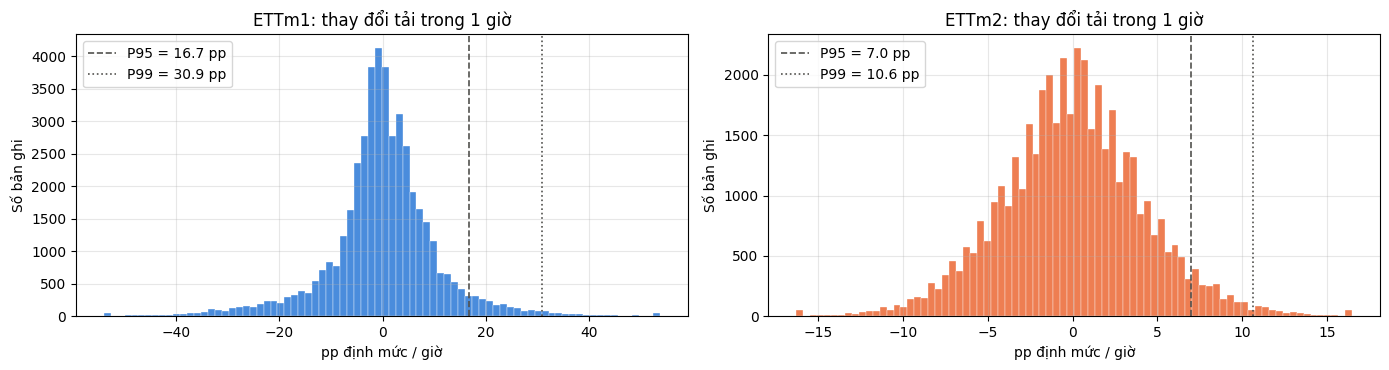

P95 tốc độ tăng 1 giờ theo giờ trong ngày (pp/giờ):


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
ETTm1,11.6,6.0,5.7,6.5,7.4,10.5,10.5,11.3,2.3,5.1,12.8,7.1,13.3,24.7,26.4,26.7,32.9,28.9,15.0,16.5,15.3,9.4,15.9,17.0
ETTm2,3.4,4.0,4.7,5.2,5.4,6.6,6.5,5.0,10.2,10.4,7.0,8.1,5.9,5.4,5.1,7.0,8.2,6.9,6.6,4.3,8.5,6.2,4.0,2.4


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (name, df) in zip(axes, data.items()):
    s = df["ramp_1h"].dropna()
    lo, hi = s.quantile([0.001, 0.999])
    ax.hist(s.clip(lo, hi), bins=80, color=COLORS[name], alpha=0.85, edgecolor="white", linewidth=0.3)
    for q, ls in [(0.95, "--"), (0.99, ":")]:
        ax.axvline(s.quantile(q), color="#52514e", ls=ls, lw=1.2, label=f"P{q*100:g} = {s.quantile(q):.1f} pp")
    ax.set(title=f"{name}: thay đổi tải trong 1 giờ", xlabel="pp định mức / giờ", ylabel="Số bản ghi")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

ramp_by_hour = pd.DataFrame({name: df.groupby("hour")["ramp_1h"].quantile(0.95) for name, df in data.items()}).T
print("P95 tốc độ tăng 1 giờ theo giờ trong ngày (pp/giờ):")
display(ramp_by_hour.round(1))

> **Giải thích kết quả.**
>
> - **Cell 15.** Một ramp chỉ được tính khi **mọi** bản ghi trong cửa sổ đều sạch, vì vậy không còn ramp nào vắt qua đoạn FLATLINE hay ngày 31. Khoảng 45.000 ramp hợp lệ mỗi cửa sổ. Đơn vị là pp định mức với hệ số 1,25.
> - Tốc độ tăng 1 giờ: P95 / P99 = **16,7 / 30,9 pp** (ETTm1) và **7,0 / 10,6 pp** (ETTm2). ETTm1 biến động gấp khoảng 3 lần ETTm2, cả hai đều gần đối xứng quanh 0.
> - **Cell 16 (theo giờ).** ETTm1 tăng nhanh nhất lúc 13–17h (P95 25–33 pp/giờ). Đây là lúc điện mặt trời giảm dần nên tải ròng "lộ ra" (suy luận, chưa kiểm chứng). ETTm2 tăng nhanh nhất lúc 8–9h (~10 pp/giờ).
> - **Ý nghĩa cho kịch bản bơm.** Ví dụ 85% → 110% trong 2 giờ = 12,5 pp/giờ. Ở ETTm2 tốc độ này vượt P99 tự nhiên (10,6), nên là bất thường thật. Ở ETTm1 nó còn dưới P95 (16,7), nên không phân biệt được với biến động thường ngày. Vì vậy tốc độ sự cố phải đặt **riêng theo trạm** (Section 8).

## Section 6. Bước (3): Spike tự nhiên, offline và real-time

Hai bộ lọc Hampel, khác nhau ở chỗ **có nhìn tương lai hay không**:

| | Offline (mô tả dữ liệu) | Real-time (mô phỏng hệ thống) |
|---|---|---|
| Mức tham chiếu | Trung vị cửa sổ **giữa** ±1 giờ (gồm cả 4 bản ghi tương lai) | Trung vị **2 giờ trước** (8 bản ghi quá khứ) |
| Thang đo | MAD trượt 7 ngày, cửa sổ giữa | MAD của 7 ngày **trước** |
| Dùng để | Đếm "có bao nhiêu spike trong dữ liệu" | Ước lượng "hệ thống thật sẽ báo bao nhiêu lần" |

Bộ lọc real-time không phân biệt được ngay spike (nhảy rồi về) với bước nhảy (nhảy rồi ở lại). Nó chỉ thấy "vừa nhảy". Muốn khẳng định là spike phải đợi thêm 1–2 bản ghi (15–30 phút) xem tải có quay về không.

In [ ]:
HAMPEL_K = [4, 6, 8]
for name, df in data.items():
    x = df["total_load"].where(df["ok"])
    # Offline: cửa sổ giữa
    med_c = x.rolling(9, center=True, min_periods=5).median()
    dev_c = x - med_c
    sc_c = dev_c.abs().rolling(96 * 7, center=True, min_periods=96).median() * 1.4826
    df["hampel_offline"] = dev_c / sc_c
    # Real-time: chỉ quá khứ
    med_p = x.shift(1).rolling(8, min_periods=5).median()
    dev_p = x - med_p
    sc_p = dev_p.abs().shift(1).rolling(96 * 7, min_periods=96).median() * 1.4826
    df["hampel_rt"] = dev_p / sc_p

rows = []
for name, df in data.items():
    for part, m in [("TRAIN", df.is_train), ("VALID", ~df.is_train)]:
        n_days = df.loc[m, "date"].dt.normalize().nunique()
        for k in HAMPEL_K:
            for col, mode in [("hampel_offline", "offline"), ("hampel_rt", "real-time")]:
                up, _ = count_episodes((df[col] > k) & m)
                down, _ = count_episodes((df[col] < -k) & m)
                rows.append({"Trạm": name, "Giai đoạn": part, "k": k, "Bộ lọc": mode,
                             "Spike lên / ngày": up / n_days, "Spike xuống / ngày": down / n_days})
spike_table = (pd.DataFrame(rows).set_index(["Trạm", "Giai đoạn", "k", "Bộ lọc"]).unstack("Bộ lọc").round(3))
spike_table.to_csv(f"{OUT_DIR}/natural_spikes.csv")
display(spike_table)

Spike lên / ngày           Spike xuống / ngày          
Bộ lọc                     offline real-time            offline real-time
Trạm  Giai đoạn k                                                        
ETTm1 TRAIN     4            2.310     0.504              2.841     0.636
                6            1.258     0.030              1.507     0.140
                8            0.937     0.011              1.101     0.027
      VALID     4            3.195     0.626              4.122     1.098
                6            1.748     0.138              2.390     0.309
                8            1.098     0.024              1.569     0.081
ETTm2 TRAIN     4            0.205     0.058              0.679     0.082
                6            0.022     0.011              0.041     0.003
                8            0.003     0.003              0.005     0.000
      VALID     4            0.293     0.130              0.789     0.130
                6            0.041     0.033              0.122     0.033
                8            0.024     0.008              0.041     0.016

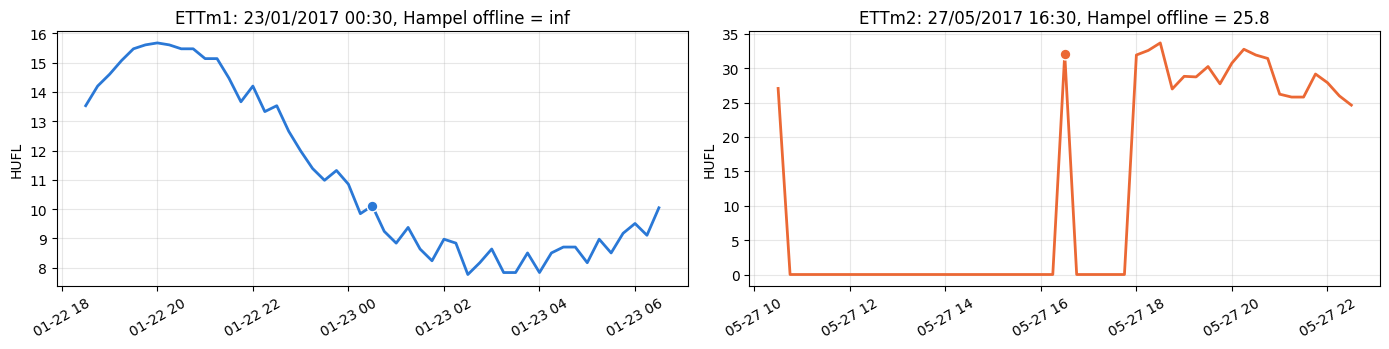

In [ ]:
# Spike lên lớn nhất (offline) của mỗi trạm, ±6 giờ
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, (name, df) in zip(axes, data.items()):
    i = df["hampel_offline"].idxmax()
    w = df.iloc[max(i - 24, 0): i + 25]
    ax.plot(w["date"], w["total_load"], lw=2, color=COLORS[name])
    ax.scatter(df.loc[[i], "date"], df.loc[[i], "total_load"], s=60, color=COLORS[name], edgecolor="white", zorder=3)
    ax.set_title(f"{name}: {df.loc[i, 'date']:%d/%m/%Y %H:%M}, Hampel offline = {df.loc[i, 'hampel_offline']:.1f}")
    ax.set_ylabel("HUFL"); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

> **Giải thích kết quả.**
>
> - **Cell 17.** Hai bộ lọc cho hai mục đích khác nhau:
>   - *Offline* (cửa sổ giữa, nhìn cả 1 giờ sau): dùng để **mô tả** dữ liệu lịch sử và chọn biên độ spike bơm.
>   - *Real-time* (chỉ nhìn 2 giờ trước, MAD 7 ngày trước): đây là thứ pipeline thật sự có, dùng để **ước lượng số cảnh báo** khi vận hành.
> - Real-time bắt ít hơn nhiều. Ví dụ với k = 6 ở ETTm1 TRAIN: offline 1,26 spike lên/ngày, real-time chỉ 0,03. Real-time không thấy giá trị đã quay về sau đó nên không "xác nhận" được spike, và thang MAD quá khứ rộng hơn.
> - Spike là chuyện **bình thường ở ETTm1** (offline ~1,3–1,7 spike lên/ngày) nhưng **hiếm ở ETTm2** (~0,02–0,04). Spike xuống nhiều hơn spike lên ở cả hai trạm.
> - VALID (07–10/2017) có nhiều spike hơn TRAIN ở cả hai trạm (ví dụ ETTm1 real-time k = 6: 0,03 → 0,14 spike lên/ngày). Mùa hè–thu biến động hơn, nên ngưỡng ước lượng trên một mùa có thể không đúng cho mùa khác.
> - **Cell 18.** Spike lớn nhất của mỗi trạm, ±6 giờ, để team xem bằng mắt.

## Section 7. Ngưỡng z-score

**Vì sao không gọi là "false alarm".** Dữ liệu ETT không có nhãn sự cố, nên một lần vượt ngưỡng trên dữ liệu thật có thể là cảnh báo giả, **cũng có thể là sự kiện thật** (như đợt 17–19/04/2017 của ETTm2). Vì vậy notebook gọi đó là **"tỷ lệ vượt ngưỡng nền"**: số lần hệ thống sẽ báo trên dữ liệu không bơm sự cố. Con số này là **ngân sách cảnh báo** (người trực sẽ phải xem bao nhiêu cảnh báo mỗi ngày), là cận trên của tỷ lệ cảnh báo giả.

**Cách chọn ngưỡng.**
1. Tính z bằng profile của **TRAIN**.
2. Trên TRAIN, chọn ngưỡng nhỏ nhất sao cho số đợt vượt (kéo dài ≥ 30 phút) không quá: **Vàng ≤ 0,10 đợt/trạm/ngày**, **Đỏ ≤ 0,02 đợt/trạm/ngày**. Lấy trạm khó hơn để ra một ngưỡng chung.
3. Áp ngưỡng đó lên **VALID** (chưa dùng để chọn) để xem tỷ lệ có giữ được không.

Chỉ xét chiều **tăng**, vì hệ thống cảnh báo quá tải.

In [ ]:
def add_z(df: pd.DataFrame, prof: pd.DataFrame, prof_r: pd.DataFrame) -> pd.DataFrame:
    df = df.drop(columns=[c for c in ["mu", "sd", "mu_r", "sd_r"] if c in df], errors="ignore")
    df = df.join(prof[["mean", "std"]].rename(columns={"mean": "mu", "std": "sd"}), on=["dow", "hour"])
    df = df.join(prof_r[["mean", "std"]].rename(columns={"mean": "mu_r", "std": "sd_r"}), on=["dow", "hour"])
    df["z"] = (df["total_load"] - df["mu"]) / df["sd"]
    df["z_resid"] = (df["resid_7d"] - df["mu_r"]) / df["sd_r"]
    return df

for name in STATIONS:
    data[name] = add_z(data[name], profiles_train[name], profiles_resid_train[name])

TARGET = {"Vàng": 0.10, "Đỏ": 0.02}
GRID = np.round(np.arange(2.0, 5.01, 0.25), 2)
Z_VARIANTS = {"z thô": "z", "z phần dư": "z_resid"}

def exceed_rate(df, zcol, t, part_mask):
    n_days = df.loc[part_mask, "date"].dt.normalize().nunique()
    ev, _ = count_episodes(((df[zcol] > t) & df["ok"] & part_mask), 2)
    return ev / n_days

rows = []
for name, df in data.items():
    for vlabel, zcol in Z_VARIANTS.items():
        for t in GRID:
            rows.append({"Biến thể": vlabel, "Trạm": name, "t": t,
                         "TRAIN": exceed_rate(df, zcol, t, df.is_train),
                         "VALID": exceed_rate(df, zcol, t, ~df.is_train)})
rates = pd.DataFrame(rows)

def pick_threshold(rate_max: pd.Series, target: float):
    """Ngưỡng nhỏ nhất t sao cho MỌI ngưỡng >= t đều có tỷ lệ <= target."""
    ok = (rate_max <= target)[::-1].cummin()[::-1]
    return float(ok[ok].index.min()) if ok.any() else None

z_threshold, check_rows = {}, []
for vlabel in Z_VARIANTS:
    r = rates[rates["Biến thể"] == vlabel]
    train_max = r.pivot(index="t", columns="Trạm", values="TRAIN").max(axis=1)
    z_threshold[vlabel] = {lvl: pick_threshold(train_max, tg) for lvl, tg in TARGET.items()}
    for lvl, t in z_threshold[vlabel].items():
        for name in STATIONS:
            row = r[(r["Trạm"] == name) & (r["t"] == t)].iloc[0]
            check_rows.append({"Biến thể": vlabel, "Mức": lvl, "Ngưỡng z": t, "Trạm": name,
                               "Mục tiêu (đợt/ngày)": TARGET[lvl],
                               "TRAIN (đợt/ngày)": row["TRAIN"], "VALID ngoài mẫu (đợt/ngày)": row["VALID"]})
z_check = pd.DataFrame(check_rows).set_index(["Biến thể", "Mức", "Trạm"]).round(3)
display(z_check)
pd.DataFrame(z_threshold).T.to_csv(f"{OUT_DIR}/z_threshold.csv")
rates.round(4).to_csv(f"{OUT_DIR}/zscore_exceedance_rates.csv", index=False)

Ngưỡng z  Mục tiêu (đợt/ngày)  TRAIN (đợt/ngày)  VALID ngoài mẫu (đợt/ngày)
Biến thể  Mức  Trạm                                                                              
z thô     Vàng ETTm1      2.75                 0.10             0.099                       0.179
               ETTm2      2.75                 0.10             0.000                       0.000
          Đỏ   ETTm1      3.50                 0.02             0.008                       0.073
               ETTm2      3.50                 0.02             0.000                       0.000
z phần dư Vàng ETTm1      2.50                 0.10             0.068                       0.325
               ETTm2      2.50                 0.10             0.079                       0.130
          Đỏ   ETTm1      3.50                 0.02             0.005                       0.154
               ETTm2      3.50                 0.02             0.011                       0.065

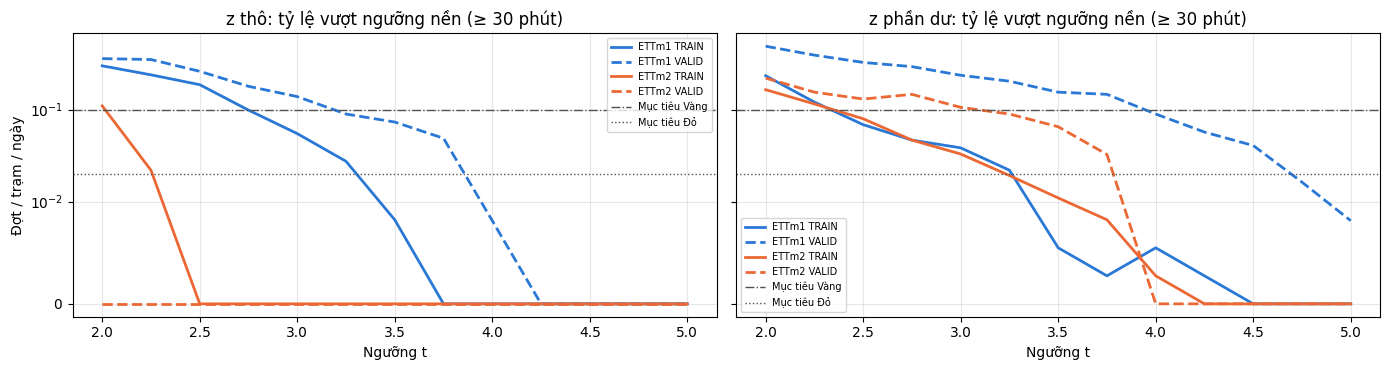

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, vlabel in zip(axes, Z_VARIANTS):
    r = rates[rates["Biến thể"] == vlabel]
    for name in STATIONS:
        rr = r[r["Trạm"] == name]
        ax.plot(rr["t"], rr["TRAIN"], lw=2, color=COLORS[name], label=f"{name} TRAIN")
        ax.plot(rr["t"], rr["VALID"], lw=2, ls="--", color=COLORS[name], label=f"{name} VALID")
    for lvl, tg in TARGET.items():
        ax.axhline(tg, color="#52514e", lw=1, ls=":" if lvl == "Đỏ" else "-.", label=f"Mục tiêu {lvl}")
    ax.set_yscale("symlog", linthresh=0.01)
    ax.set(title=f"{vlabel}: tỷ lệ vượt ngưỡng nền (≥ 30 phút)", xlabel="Ngưỡng t")
    ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("Đợt / trạm / ngày")
plt.tight_layout(); plt.show()

> **Giải thích kết quả.**
>
> - **Cell 19 (cách chọn ngưỡng).** Ngưỡng được chọn trên TRAIN theo **ngân sách cảnh báo**: Vàng ≤ 0,10 đợt (≥ 30 phút)/trạm/ngày, Đỏ ≤ 0,02. Dùng chung cho hai trạm (lấy theo trạm khó hơn). Kết quả: z thô Vàng **2,75** / Đỏ **3,5**; z phần dư Vàng **2,5** / Đỏ **3,5**.
> - **Ngoài mẫu (VALID).** Tỷ lệ vượt cao hơn mục tiêu, nhất là ETTm1: z thô Vàng 0,18 đợt/ngày (gấp 1,8 lần), z phần dư Vàng 0,33 (gấp 3,3), z phần dư Đỏ 0,15 (gấp 7,7). ETTm2 z thô **không bật lần nào** vì std thô lớn (mức tải trôi), nên z thô gần như vô dụng ở ETTm2.
> - **Vì sao không gọi là false alarm.** Dữ liệu không có nhãn sự cố, nên không biết lượt vượt nào là báo sai và lượt nào là biến động thật của mùa hè–thu. Notebook gọi là **"tỷ lệ vượt ngưỡng nền"**.
> - **Cell 20.** Đường VALID (nét đứt) nằm trên đường TRAIN (nét liền) ở hầu hết các ngưỡng, nghĩa là ngưỡng **không giữ được ngoài mẫu**. Các con số z là tạm. Hai hướng xử lý: cập nhật profile định kỳ (rolling), hoặc chấp nhận ngân sách cao hơn. Tham số xuất cho pipeline đã ước lượng trên đủ 16 tháng (gồm cả VALID), nên phần nào đã bao mùa hè–thu.

## Section 8. Biên độ sự cố bơm vào và kiểm chứng bằng Monte Carlo

**Kịch bản quá tải dần (`OVERLOAD_RAMP`).** Cộng thêm vào tải thật một lượng tăng tuyến tính trong `rise_h` giờ, sao cho tại đỉnh tải đạt `peak_pct`% định mức; giữ 1 giờ; giảm về trong 1 giờ. Dao động tự nhiên được giữ nguyên.

**Kiểm chứng.** Bơm **hàng trăm sự cố** vào các thời điểm ngẫu nhiên của **VALID** (dữ liệu chưa dùng để chọn ngưỡng). Mỗi lần bơm, xem từng tầng phát hiện báo **lần đầu** lúc nào so với `t_breach` (lúc tải vượt 100% định mức):

| Tầng | Quy tắc báo |
|---|---|
| Ngưỡng `load_pct` | `load_pct ≥ 100%` (theo định nghĩa báo đúng lúc breach, lead time = 0) |
| z thô / z phần dư (Vàng) | z vượt ngưỡng Vàng ở Section 7 |
| Ngoại suy xu hướng | Độ dốc 1 giờ gần nhất > 0 và thời gian dự kiến tới 100% ≤ 60 phút |

Chỉ chọn thời điểm bắt đầu mà cửa sổ sự cố sạch và tải lúc bắt đầu < 90% định mức.

In [ ]:
def first_alert_times(seg: pd.DataFrame, zthr: dict) -> dict:
    """Thời điểm báo đầu tiên của từng tầng trên một đoạn dữ liệu (đã bơm)."""
    out = {}
    out["z thô"] = seg.loc[seg["z"] > zthr["z thô"]["Vàng"], "date"].min()
    out["z phần dư"] = seg.loc[seg["z_resid"] > zthr["z phần dư"]["Vàng"], "date"].min()
    slope = seg["slope_1h"]                                          # pp / giờ, tính trước khi cắt phần đệm
    ttb_min = (100 - seg["load_pct"]) / slope * 60
    out["Ngoại suy xu hướng"] = seg.loc[(slope > 0) & (ttb_min <= 60) & (seg["load_pct"] < 100), "date"].min()
    return out

def simulate(name, n, rise_h, peak_pct, coef, zthr, hold_h=1.0, fall_h=1.0, rng=RNG):
    df = data[name]
    pct = df["total_load"] / (P99[name] * coef) * 100          # load_pct theo hệ số đang xét
    n_rise, n_hold, n_fall = int(rise_h * 4), int(hold_h * 4), int(fall_h * 4)
    L = n_rise + n_hold + n_fall
    shape = np.r_[np.linspace(0, 1, n_rise + 1)[1:], np.ones(n_hold), np.linspace(1, 0, n_fall + 1)[1:]]
    valid_idx = df.index[(~df.is_train) & df["ok"].astype(int).rolling(L + 9).min().shift(-(L + 1)).eq(1)
                         & (pct < 90)]
    results = []
    for i0 in rng.choice(valid_idx, size=min(n, len(valid_idx)), replace=False):
        idx = np.arange(i0 - 8, i0 + 1 + L)
        seg = df.loc[idx, ["date", "total_load", "mu", "sd", "baseline_7d", "mu_r", "sd_r"]].copy()
        base_pct = pct.loc[idx].values
        add = np.zeros(len(idx))
        add_peak = max(peak_pct - base_pct[8 + n_rise], 0)
        add[9:] = add_peak * shape
        seg["load_pct"] = base_pct + add
        seg["total_load"] = seg["load_pct"] * P99[name] * coef / 100
        seg["z"] = (seg["total_load"] - seg["mu"]) / seg["sd"]
        seg["z_resid"] = (seg["total_load"] - seg["baseline_7d"] - seg["mu_r"]) / seg["sd_r"]
        seg["slope_1h"] = seg["load_pct"].diff(4)                   # cần 8 bản ghi đệm phía trước để có độ dốc ngay từ đầu
        seg = seg.iloc[8:]                                          # bỏ phần đệm quá khứ
        t_start = seg["date"].iloc[0]
        t_breach = seg.loc[seg["load_pct"] >= 100, "date"].min()
        alerts = first_alert_times(seg.iloc[1:], zthr)
        row = {"Trạm": name, "rise_h": rise_h, "peak_pct": peak_pct, "coef": coef,
               "rate_pp_per_h": add_peak / rise_h, "t_start": t_start, "t_breach": t_breach}
        for k, t in alerts.items():
            row[f"{k}: báo trước breach"] = bool(pd.notna(t) and pd.notna(t_breach) and t < t_breach)
            row[f"{k}: lead (phút)"] = (t_breach - t).total_seconds() / 60 if pd.notna(t) and pd.notna(t_breach) else np.nan
        results.append(row)
    return pd.DataFrame(results)

N_SIM = 200
scenarios = [(1, 110), (2, 110), (3, 110), (2, 120)]
mc = pd.concat([simulate(name, N_SIM, r, p, RATING_COEF, z_threshold) for name in STATIONS for r, p in scenarios],
               ignore_index=True)
mc.to_csv(f"{OUT_DIR}/mc_overload_runs.csv", index=False)

def summarize(mc):
    tiers = list(Z_VARIANTS) + ["Ngoại suy xu hướng"]
    g = mc.groupby(["Trạm", "rise_h", "peak_pct", "coef"])
    out = pd.DataFrame({"Số lần bơm": g.size(), "Tốc độ TB (pp/giờ)": g["rate_pp_per_h"].mean()})
    for t in tiers:
        out[f"{t}: % báo trước"] = g[f"{t}: báo trước breach"].mean() * 100
        out[f"{t}: lead trung vị (phút)"] = g[f"{t}: lead (phút)"].median()
    return out.round(1)

mc_summary = summarize(mc)
mc_summary.to_csv(f"{OUT_DIR}/mc_overload_summary.csv")
print(f"RATING_COEF = {RATING_COEF}; {N_SIM} sự cố mỗi kịch bản mỗi trạm, bơm vào VALID")
display(mc_summary)

RATING_COEF = 1.25; 200 sự cố mỗi kịch bản mỗi trạm, bơm vào VALID


Số lần bơm  Tốc độ TB (pp/giờ)  z thô: % báo trước  z thô: lead trung vị (phút)  z phần dư: % báo trước  z phần dư: lead trung vị (phút)  \
Trạm  rise_h peak_pct coef                                                                                                                                             
ETTm1 1      110      1.25         200                83.2                70.0                         15.0                    83.5                             30.0   
      2      110      1.25         200                40.7                75.0                         30.0                    92.5                             45.0   
             120      1.25         200                48.3                73.0                         30.0                    92.0                             45.0   
      3      110      1.25         200                27.1                77.5                         45.0                    96.5                             75.0   
ETTm2 1      110      1.25         200                62.5                83.5                         15.0                   100.0                             30.0   
      2      110      1.25         200                31.4                87.0                         15.0                   100.0                             60.0   
             120      1.25         200                36.3                83.0                         15.0                   100.0                             60.0   
      3      110      1.25         200                20.7                89.5                         30.0                   100.0                            105.0   

                            Ngoại suy xu hướng: % báo trước  Ngoại suy xu hướng: lead trung vị (phút)  
Trạm  rise_h peak_pct coef                                                                             
ETTm1 1      110      1.25                             97.0                                      30.0  
      2      110      1.25                             99.0                                      45.0  
             120      1.25                             99.0                                      45.0  
      3      110      1.25                             99.0                                      60.0  
ETTm2 1      110      1.25                            100.0                                      30.0  
      2      110      1.25                            100.0                                      45.0  
             120      1.25                            100.0                                      45.0  
      3      110      1.25                            100.0                                      60.0

In [ ]:
# Mặt "chi phí": trên VALID KHÔNG bơm gì, mỗi tầng tự bật bao nhiêu đợt (>= 2 bản ghi) mỗi ngày?
# Tỷ lệ phát hiện cao chỉ có ý nghĩa khi đặt cạnh tỷ lệ này. Đây là "tỷ lệ báo nền", chưa phải false alarm
# (dữ liệu không có nhãn sự cố thật nên không biết lượt nào là báo sai).
base_rows = []
for name, df in data.items():
    v = df[~df.is_train].copy()
    n_days = v["date"].dt.normalize().nunique()
    slope = v["load_pct"].diff(4)
    ttb = (100 - v["load_pct"]) / slope * 60
    masks = {"z thô": v["z"] > z_threshold["z thô"]["Vàng"],
             "z phần dư": v["z_resid"] > z_threshold["z phần dư"]["Vàng"],
             "Ngoại suy xu hướng": (slope > 0) & (ttb <= 60) & (v["load_pct"] < 100)}
    for tier, m in masks.items():
        ev, _ = count_episodes(m & v["ok"], 2)
        base_rows.append({"Trạm": name, "Tầng": tier, "Đợt báo / ngày (VALID, không bơm)": round(ev / n_days, 3)})
base_rate = pd.DataFrame(base_rows).pivot(index="Tầng", columns="Trạm", values="Đợt báo / ngày (VALID, không bơm)")
base_rate.to_csv(f"{OUT_DIR}/alert_base_rate_valid.csv")
print(f"RATING_COEF = {RATING_COEF}; đơn vị: đợt báo / trạm / ngày")
display(base_rate)

RATING_COEF = 1.25; đơn vị: đợt báo / trạm / ngày


Trạm,ETTm1,ETTm2
Tầng,,
Ngoại suy xu hướng,0.122,0.008
z phần dư,0.325,0.130
z thô,0.179,0.000


In [ ]:
# Độ nhạy theo hệ số định mức: cùng kịch bản 'tăng lên 110% trong 2 giờ'
mc_coef = pd.concat([simulate(name, N_SIM, 2, 110, coef, z_threshold) for name in STATIONS for coef in COEF_GRID],
                    ignore_index=True)
display(summarize(mc_coef))

Số lần bơm  Tốc độ TB (pp/giờ)  z thô: % báo trước  z thô: lead trung vị (phút)  z phần dư: % báo trước  z phần dư: lead trung vị (phút)  \
Trạm  rise_h peak_pct coef                                                                                                                                             
ETTm1 2      110      1.00         200                37.4                24.5                          0.0                    64.0                             15.0   
                      1.25         200                41.3                76.5                         30.0                    92.5                             45.0   
                      1.50         200                43.7                91.5                         45.0                    99.0                             60.0   
ETTm2 2      110      1.00         200                24.8                 2.0                        -15.0                    91.5                             45.0   
                      1.25         200                31.1                88.0                         30.0                   100.0                             75.0   
                      1.50         200                35.3               100.0                         45.0                   100.0                             75.0   

                            Ngoại suy xu hướng: % báo trước  Ngoại suy xu hướng: lead trung vị (phút)  
Trạm  rise_h peak_pct coef                                                                             
ETTm1 2      110      1.00                             99.0                                      45.0  
                      1.25                             99.0                                      45.0  
                      1.50                            100.0                                      45.0  
ETTm2 2      110      1.00                            100.0                                      45.0  
                      1.25                            100.0                                      45.0  
                      1.50                            100.0                                      45.0

In [ ]:
# Spike giả lập: +A pp trong 1 bản ghi, phát hiện bằng Hampel REAL-TIME (k = 6)
jump15 = {name: df["ramp_15m"].abs().quantile(0.999) for name, df in data.items()}
spike_rows = []
for name, df in data.items():
    x = df["total_load"].where(df["ok"])
    dev_p = x - x.shift(1).rolling(8, min_periods=5).median()
    scale = (dev_p.abs().shift(1).rolling(96 * 7, min_periods=96).median() * 1.4826)
    cand = df.index[(~df.is_train) & df["ok"] & scale.notna() & dev_p.notna()]
    picks = RNG.choice(cand, size=min(N_SIM, len(cand)), replace=False)
    for mult in [1.0, 2.0]:
        amp_pp = mult * jump15[name]
        amp = amp_pp * P99[name] * RATING_COEF / 100
        score = (dev_p.loc[picks] + amp) / scale.loc[picks]
        spike_rows.append({"Trạm": name, "Biên độ": f"{mult:g} × P99,9 bước nhảy 15 phút",
                           "Biên độ (pp định mức)": round(amp_pp, 1),
                           "% phát hiện (Hampel real-time, k=6)": round((score > 6).mean() * 100, 1)})
spike_mc = pd.DataFrame(spike_rows).set_index(["Trạm", "Biên độ"])
spike_mc.to_csv(f"{OUT_DIR}/mc_spike_summary.csv")
display(spike_mc)

Biên độ (pp định mức)  % phát hiện (Hampel real-time, k=6)
Trạm  Biên độ                                                                                
ETTm1 1 × P99,9 bước nhảy 15 phút                   44.8                                 46.0
      2 × P99,9 bước nhảy 15 phút                   89.5                                 96.5
ETTm2 1 × P99,9 bước nhảy 15 phút                   11.9                                  0.5
      2 × P99,9 bước nhảy 15 phút                   23.8                                 81.0

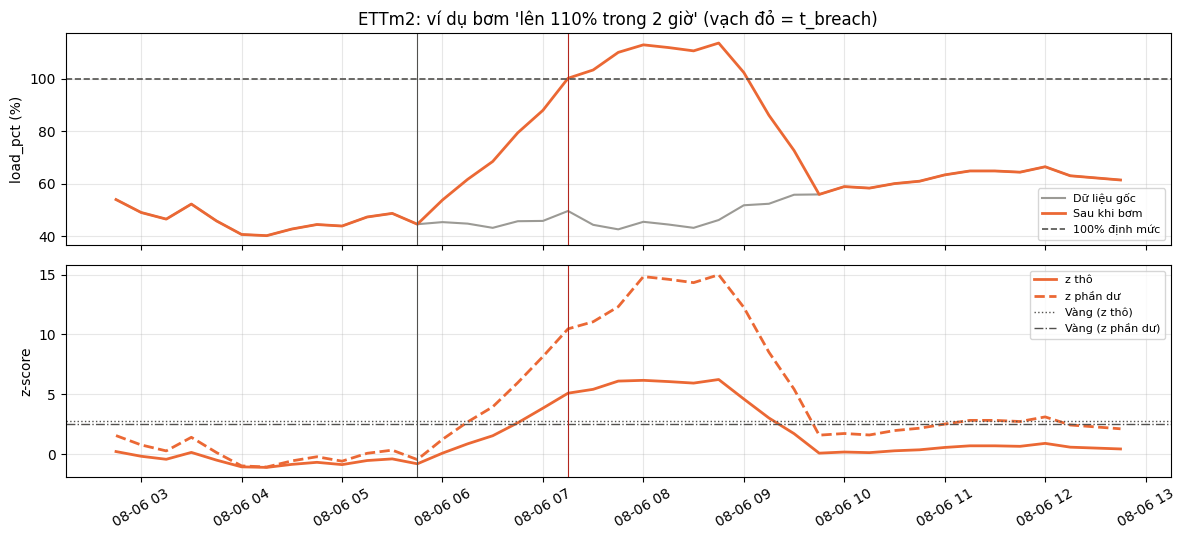

In [ ]:
# Một ví dụ minh hoạ: 1 sự cố 'lên 110% trong 2 giờ' trên ETTm2, xem các tầng phản ứng
name = "ETTm2"
ex = mc[(mc["Trạm"] == name) & (mc["rise_h"] == 2) & (mc["peak_pct"] == 110)].iloc[0]
df = data[name]
i0 = df.index[df["date"] == ex["t_start"]][0]
idx = np.arange(i0 - 12, i0 + 1 + 16 + 12)
seg = df.loc[idx, ["date", "load_pct", "z", "z_resid"]].copy()
shape = np.r_[np.linspace(0, 1, 9)[1:], np.ones(4), np.linspace(1, 0, 5)[1:]]
add = np.zeros(len(idx)); add_peak = max(110 - df.at[i0 + 8, "load_pct"], 0); add[13:13 + len(shape)] = add_peak * shape
inj_pct = seg["load_pct"].values + add
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(seg["date"], seg["load_pct"], color="#9b9a95", lw=1.5, label="Dữ liệu gốc")
axes[0].plot(seg["date"], inj_pct, color=COLORS[name], lw=2, label="Sau khi bơm")
axes[0].axhline(100, color="#52514e", ls="--", lw=1.2, label="100% định mức")
axes[0].set_ylabel("load_pct (%)"); axes[0].legend(fontsize=8)
inj_load = inj_pct * P99[name] * RATING_COEF / 100
z_inj = (inj_load - df.loc[idx, "mu"].values) / df.loc[idx, "sd"].values
zr_inj = (inj_load - df.loc[idx, "baseline_7d"].values - df.loc[idx, "mu_r"].values) / df.loc[idx, "sd_r"].values
axes[1].plot(seg["date"], z_inj, color=COLORS[name], lw=2, label="z thô")
axes[1].plot(seg["date"], zr_inj, color=COLORS[name], lw=2, ls="--", label="z phần dư")
axes[1].axhline(z_threshold["z thô"]["Vàng"], color="#52514e", lw=1, ls=":", label="Vàng (z thô)")
axes[1].axhline(z_threshold["z phần dư"]["Vàng"], color="#52514e", lw=1, ls="-.", label="Vàng (z phần dư)")
axes[1].set_ylabel("z-score"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.axvline(ex["t_start"], color="#52514e", lw=0.8)
    if pd.notna(ex["t_breach"]):
        ax.axvline(ex["t_breach"], color="#b3261e", lw=0.8)
    ax.grid(alpha=0.3)
axes[0].set_title(f"{name}: ví dụ bơm 'lên 110% trong 2 giờ' (vạch đỏ = t_breach)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

In [ ]:
# Bảng tham số sự cố đề xuất (neo vào thống kê của TRAIN + VALID, hệ số mặc định)
inj_rows = []
for name, df in data.items():
    ok = df[df.ok]
    p85 = ok["load_pct"].quantile(0.85)
    r1h = df["ramp_1h"].dropna()
    p95, p99 = r1h.quantile([0.95, 0.99])
    for peak in [110, 120]:
        inj_rows.append({"Trạm": name, "Loại": f"OVERLOAD_RAMP → {peak}%",
                         "Điển hình bắt đầu từ (P85, % định mức)": round(p85, 1),
                         "Tốc độ (pp/giờ, P95–P99 tự nhiên)": f"{p95:.1f} – {p99:.1f}",
                         "Thời gian tăng (giờ)": f"{(peak - p85) / p99:.1f} – {(peak - p85) / p95:.1f}",
                         "Giữ / giảm": "giữ 1–2 giờ, giảm 1–2 giờ"})
    inj_rows.append({"Trạm": name, "Loại": "SPIKE", "Điển hình bắt đầu từ (P85, % định mức)": "mức hiện tại",
                     "Tốc độ (pp/giờ, P95–P99 tự nhiên)": f"biên độ ≥ {2 * jump15[name]:.1f} pp (2 × P99,9 bước 15 phút)",
                     "Thời gian tăng (giờ)": "tức thời", "Giữ / giảm": "1–2 bản ghi (15–30 phút)"})
    inj_rows.append({"Trạm": name, "Loại": "SENSOR_FAULT", "Điển hình bắt đầu từ (P85, % định mức)": "mức hiện tại",
                     "Tốc độ (pp/giờ, P95–P99 tự nhiên)": "giữ nguyên giá trị hoặc rơi về 0",
                     "Thời gian tăng (giờ)": "—", "Giữ / giảm": f"2–6 giờ (luật FLATLINE báo sau {FLAT_MIN_RECORDS} bản ghi)"})
inj_table = pd.DataFrame(inj_rows).set_index(["Trạm", "Loại"])
inj_table.to_csv(f"{OUT_DIR}/injection_params.csv")
display(inj_table)

Điển hình bắt đầu từ (P85, % định mức)           Tốc độ (pp/giờ, P95–P99 tự nhiên) Thời gian tăng (giờ)                                 Giữ / giảm
Trạm  Loại                                                                                                                                                                   
ETTm1 OVERLOAD_RAMP → 110%                                   53.9                                 16.7 – 30.9            1.8 – 3.4                  giữ 1–2 giờ, giảm 1–2 giờ
      OVERLOAD_RAMP → 120%                                   53.9                                 16.7 – 30.9            2.1 – 3.9                  giữ 1–2 giờ, giảm 1–2 giờ
      SPIKE                                          mức hiện tại  biên độ ≥ 89.5 pp (2 × P99,9 bước 15 phút)             tức thời                   1–2 bản ghi (15–30 phút)
      SENSOR_FAULT                                   mức hiện tại            giữ nguyên giá trị hoặc rơi về 0                    —  2–6 giờ (luật FLATLINE báo sau 8 bản ghi)
ETTm2 OVERLOAD_RAMP → 110%                                   66.4                                  7.0 – 10.6            4.1 – 6.2                  giữ 1–2 giờ, giảm 1–2 giờ
      OVERLOAD_RAMP → 120%                                   66.4                                  7.0 – 10.6            5.0 – 7.7                  giữ 1–2 giờ, giảm 1–2 giờ
      SPIKE                                          mức hiện tại  biên độ ≥ 23.8 pp (2 × P99,9 bước 15 phút)             tức thời                   1–2 bản ghi (15–30 phút)
      SENSOR_FAULT                                   mức hiện tại            giữ nguyên giá trị hoặc rơi về 0                    —  2–6 giờ (luật FLATLINE báo sau 8 bản ghi)

> **Giải thích kết quả.**
>
> - **Cell 21 (cách mô phỏng).** Mỗi kịch bản bơm 200 sự cố/trạm vào thời điểm ngẫu nhiên trong VALID (dòng sạch, tải < 90%). Tải được cộng thêm theo dốc tuyến tính tới đỉnh, giữ 1 giờ rồi giảm 1 giờ. Ba tầng được thử: z thô, z phần dư (mức Vàng), và **ngoại suy xu hướng** (độ dốc 1 giờ, dự báo chạm 100% trong ≤ 60 phút).
> - **Kết quả (hệ số 1,25).** z thô báo trước khi vượt 100% trong 63–90% số lần, lead trung vị chỉ 15–45 phút. z phần dư: 83–100%, lead 30–105 phút. Ngoại suy xu hướng: 97–100%, lead 30–60 phút. Tăng càng chậm thì z càng khó bắt (ETTm1, 3 giờ: z thô chỉ 77%).
> - **Cell 22 (mặt chi phí).** Trên VALID không bơm gì, mỗi tầng tự bật: z phần dư 0,33 (ETTm1) / 0,13 (ETTm2) đợt/ngày; z thô 0,18 / 0; ngoại suy xu hướng **0,12 / 0,008**. Ngoại suy xu hướng vừa bắt nhiều nhất vừa ít báo nền nhất. **Gợi ý:** dùng ngoại suy xu hướng làm tầng cảnh báo sớm theo định mức, còn z phần dư làm tầng "bất thường so với thói quen".
> - **Cell 23 (độ nhạy hệ số).** Với hệ số 1,0, mức 100% nằm sát tải thường, nên z báo muộn (ETTm2 z thô lead trung vị −15 phút, tức báo **sau** khi đã vượt). Hệ số càng thấp, z càng kém, còn ngoại suy xu hướng gần như không đổi (91–100%).
> - **Cell 24 (spike).** Spike cao bằng 1 × P99,9 bước nhảy 15 phút chỉ bắt được 46% (ETTm1) và 0,5% (ETTm2), vì nó lẫn vào spike tự nhiên. Ở 2 × thì bắt được 96,5% / 81%. Biên độ spike bơm nên **≥ 2 × P99,9**: ~90 pp (ETTm1), ~24 pp (ETTm2).
> - **Cell 26 (bảng tham số).** Tốc độ trong bảng lấy theo P95–P99 tự nhiên, tức là kịch bản **khó** (tốc độ lẫn vào biến động thường). Các kịch bản MC ở Cell 21 nhanh hơn, tức **dễ đến trung bình**. Nên bơm cả hai loại. Thời gian giữ/giảm 1–2 giờ là lựa chọn thiết kế, không rút ra từ dữ liệu.
> - **Giới hạn:** hình dạng sự cố tuyến tính; chỉ kiểm trên 1 mùa (VALID); chưa dùng OT/mô hình nhiệt IEC; mỗi sự cố bơm độc lập, không chồng nhau.

## Section 9. Tóm tắt phát hiện chính

> **Giải thích kết quả.**
>
> Mức độ bằng chứng: **[Chắc]** kiểm tra trực tiếp trên dữ liệu; **[Khá chắc]** có kiểm tra độ nhạy hoặc ngoài mẫu; **[Giả định]** chọn có lý do nhưng dữ liệu không chứng minh được.
>
> 1. **[Chắc]** `total_load = HUFL`. FLATLINE ngưỡng 8 bản ghi gắn cờ ~2,6% (ETTm1) và ~3,6% (ETTm2), và không nhạy với ngưỡng 4–96. Ngày 31 bị lặp là lỗi dữ liệu (960 dòng/trạm).
> 2. **[Khá chắc]** Đợt cực đoan ETTm2 17–19/04/2017 có thể là sự kiện thật kèm lỗi kênh đo. Loại khỏi hiệu chuẩn chỉ làm P99 đổi −2,8%. Nên giữ làm ca kiểm thử.
> 3. **[Khá chắc]** P99 sạch: ETTm1 18,89, ETTm2 58,55. Lọc chỉ làm P99 đổi ≤ 3,4%. Mùa (±15%) và hệ số định mức mới là nguồn bất định chính.
> 4. **[Giả định]** `RATING_COEF = 1,25` (đỉnh lịch sử ≈ 80% định mức), vì hệ số 1,0 cho thấy "quá tải" thường xuyên trong khi OT còn xa giới hạn IEC. Cần nêu rõ là giả định và báo cáo độ nhạy 1,0 / 1,5.
> 5. **[Khá chắc]** Profile giờ × thứ của ETTm1 ổn định (tương quan 0,89–0,97). Của ETTm2 thì không ổn định theo ô, nên dùng std gộp.
> 6. **[Chắc]** Tốc độ tăng 1 giờ, P95 / P99: ETTm1 16,7 / 30,9 pp, ETTm2 7,0 / 10,6 pp (hệ số 1,25). Kịch bản 85 → 110% trong 2 giờ chỉ là bất thường với ETTm2.
> 7. **[Khá chắc]** Ngưỡng z (Vàng 2,5–2,75, Đỏ 3,5) đạt ngân sách trên TRAIN nhưng **vượt ngân sách trên VALID** (tới 3–8 lần ở ETTm1). Đây là tỷ lệ vượt ngưỡng nền, chưa phải false alarm.
> 8. **[Khá chắc, trên dữ liệu mô phỏng]** Ngoại suy xu hướng bắt 97–100% sự cố ramp trước khi vượt 100%, lead 30–60 phút, báo nền thấp nhất. z thô kém nhất. Kết luận này chỉ đúng với sự cố dạng dốc tuyến tính và mùa hè–thu 2017.
> 9. **Chưa làm:** gắn tầng Đỏ vào mô hình nhiệt IEC 60076-7 (dùng OT), kiểm trên 8 tháng vận hành (để dành cho đánh giá cuối).